In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Define the names of the dataset columns

columns = [
    "engine_id",
    "cycle",
    "operating_setting_1",
    "operating_setting_2",
    "operating_setting_3",
]

# Add names for the 21 sensor measurements
columns += [f"sensor_{i}" for i in range(1, 22)]

# Load the dataset
df = pd.read_csv(
    "../data/raw/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 20631
Number of columns: 26


In [4]:

df.head()


,engine_id,cycle,operating_setting_1,operating_setting_2,operating_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_id            20631 non-null  int64  
 1   cycle                20631 non-null  int64  
 2   operating_setting_1  20631 non-null  float64
 3   operating_setting_2  20631 non-null  float64
 4   operating_setting_3  20631 non-null  float64
 5   sensor_1             20631 non-null  float64
 6   sensor_2             20631 non-null  float64
 7   sensor_3             20631 non-null  float64
 8   sensor_4             20631 non-null  float64
 9   sensor_5             20631 non-null  float64
 10  sensor_6             20631 non-null  float64
 11  sensor_7             20631 non-null  float64
 12  sensor_8             20631 non-null  float64
 13  sensor_9             20631 non-null  float64
 14  sensor_10            20631 non-null  float64
 15  sensor_11            20631 non-null  float64
 1

In [6]:

df.isnull().sum()


engine_id              0
cycle                  0
operating_setting_1    0
operating_setting_2    0
operating_setting_3    0
sensor_1               0
sensor_2               0
sensor_3               0
sensor_4               0
sensor_5               0
sensor_6               0
sensor_7               0
sensor_8               0
sensor_9               0
sensor_10              0
sensor_11              0
sensor_12              0
sensor_13              0
sensor_14              0
sensor_15              0
sensor_16              0
sensor_17              0
sensor_18              0
sensor_19              0
sensor_20              0
sensor_21              0
dtype: int64

In [7]:

df.describe()


,engine_id,cycle,operating_setting_1,operating_setting_2,operating_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400



# Step 4: Exploratory Data Analysis (EDA)

In this section, we examine the NASA C-MAPSS dataset,
understand engine operating cycles, and visualize sensor readings.

In [8]:

# Count the unique engines in the dataset
total_engines = df["engine_id"].nunique()

print("Total number of engines:", total_engines)

# Show the first 10 engine IDs
print("First 10 engine IDs:")
print(df["engine_id"].unique()[:10])


Total number of engines: 100
First 10 engine IDs:
[ 1  2  3  4  5  6  7  8  9 10]


In [9]:

# Count records for each engine
cycles_per_engine = df.groupby("engine_id")["cycle"].count()

print("Cycles per engine:")
print(cycles_per_engine.head(10))

print("\nMinimum cycles:", cycles_per_engine.min())
print("Maximum cycles:", cycles_per_engine.max())
print("Average cycles:", round(cycles_per_engine.mean(), 2))


Cycles per engine:
engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

Minimum cycles: 128
Maximum cycles: 362
Average cycles: 206.31


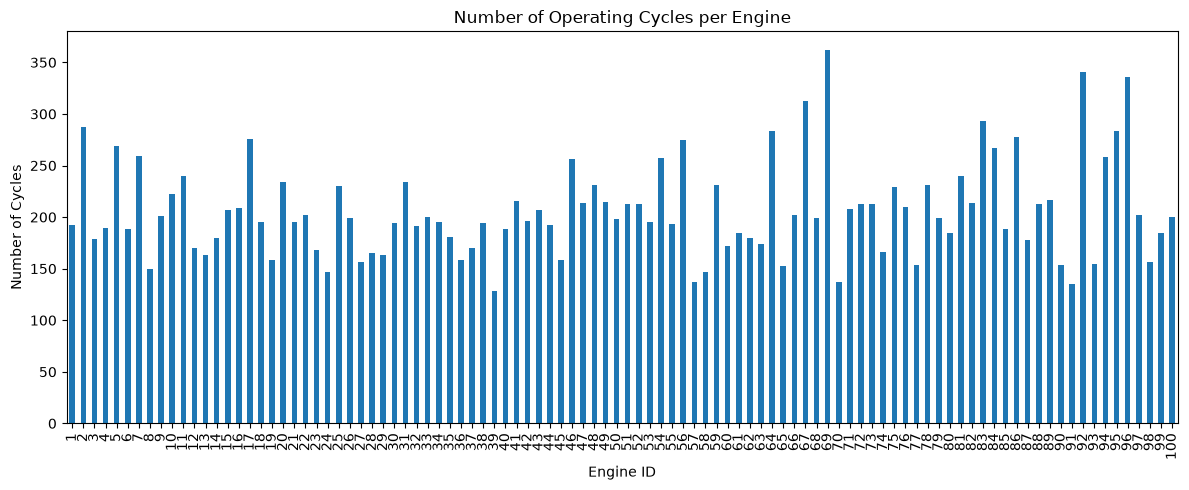

In [10]:

plt.figure(figsize=(12, 5))

cycles_per_engine.plot(kind="bar")

plt.title("Number of Operating Cycles per Engine")
plt.xlabel("Engine ID")
plt.ylabel("Number of Cycles")
plt.tight_layout()
plt.show()


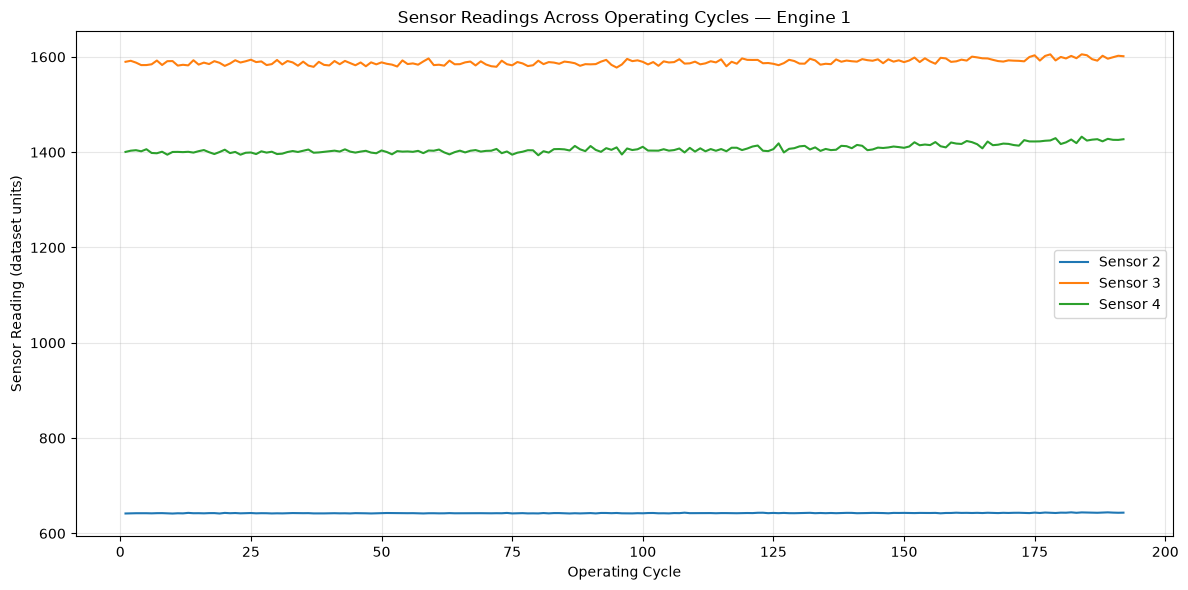

In [11]:

# Select the records for Engine 1
engine_1 = df[df["engine_id"] == 1]

# Plot three sensor readings over operating cycles
plt.figure(figsize=(12, 6))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"],
    label="Sensor 2"
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_3"],
    label="Sensor 3"
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_4"],
    label="Sensor 4"
)

plt.title("Sensor Readings Across Operating Cycles — Engine 1")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Reading (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


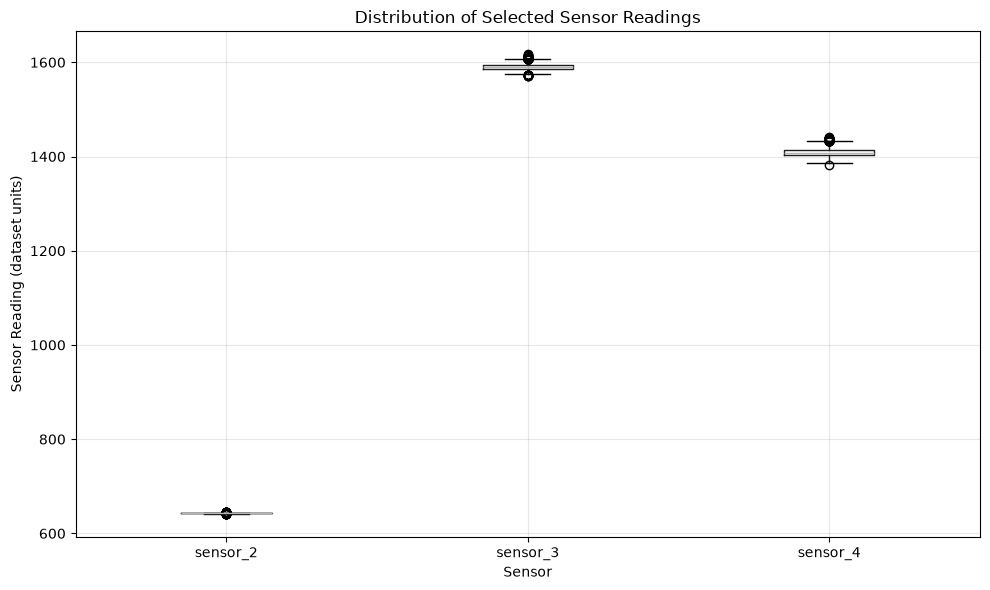

In [12]:

plt.figure(figsize=(10, 6))

df[["sensor_2", "sensor_3", "sensor_4"]].boxplot()

plt.title("Distribution of Selected Sensor Readings")
plt.xlabel("Sensor")
plt.ylabel("Sensor Reading (dataset units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# Count missing values
print("Total missing values:", df.isnull().sum().sum())

# Calculate the variation in each sensor
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

sensor_std = df[sensor_columns].std()

print("\nSensor standard deviations:")
print(sensor_std.sort_values())

# Identify sensors with zero variation
constant_sensors = sensor_std[sensor_std == 0].index.tolist()

print("\nSensors with zero variation:")
print(constant_sensors)


Total missing values: 0

Sensor standard deviations:
sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

Sensors with zero variation:
['sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']



## Initial Findings

- Examined the number of engines and operating cycles.
- Visualized sensor readings over time for one engine.
- Compared the distributions of selected sensors using boxplots.
- Checked for missing values and sensors with zero variation.

### Observations

Add your actual observations here after examining the generated charts and outputs.

### Next Steps

Investigate sensor noise, apply filtering where appropriate, and prepare sensor features for anomaly detection.



# Step 5: Noise Reduction and Sensor Data Filtering

We will apply a moving-average filter to sensor readings
and compare the original and smoothed signals.


In [14]:

# Select Engine 1 and make a separate copy
engine_1 = df[df["engine_id"] == 1].copy()

# Apply a moving-average filter to Sensor 2
engine_1["sensor_2_smoothed"] = (
    engine_1["sensor_2"]
    .rolling(window=5, min_periods=1)
    .mean()
)

# Display the first 10 readings
print(
    engine_1[
        ["cycle", "sensor_2", "sensor_2_smoothed"]
    ].head(10)
)


   cycle  sensor_2  sensor_2_smoothed
0      1    641.82         641.820000
1      2    642.15         641.985000
2      3    642.35         642.106667
3      4    642.35         642.167500
4      5    642.37         642.208000
5      6    642.10         642.264000
6      7    642.48         642.330000
7      8    642.56         642.372000
8      9    642.12         642.326000
9     10    641.71         642.194000


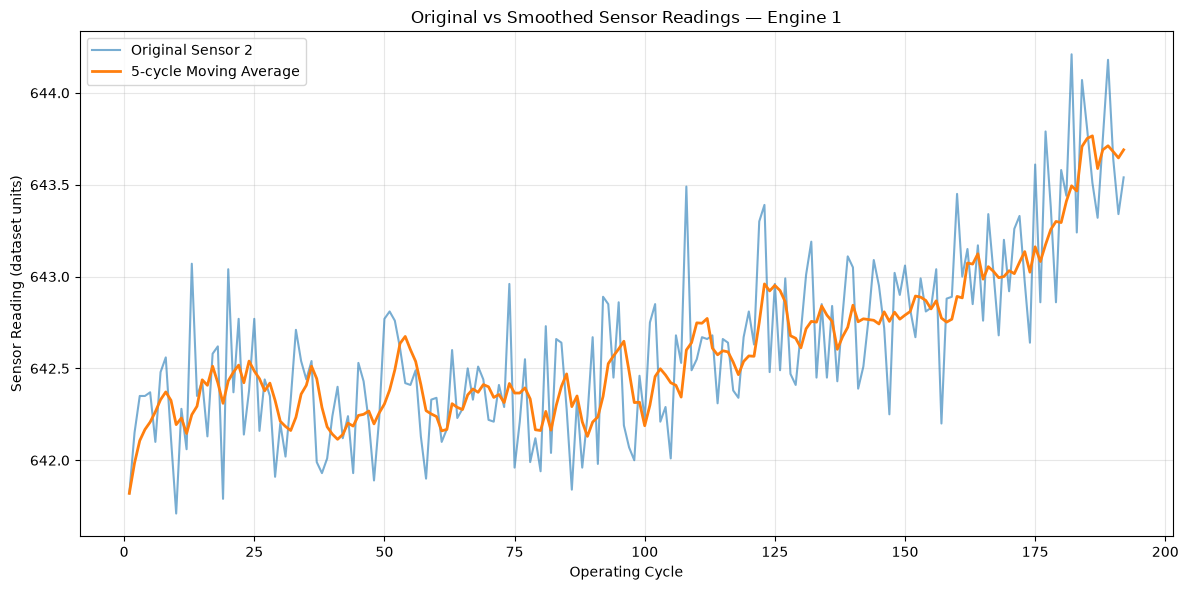

In [15]:

plt.figure(figsize=(12, 6))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"],
    label="Original Sensor 2",
    alpha=0.6
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2_smoothed"],
    label="5-cycle Moving Average",
    linewidth=2
)

plt.title("Original vs Smoothed Sensor Readings — Engine 1")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Reading (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

original_std = engine_1["sensor_2"].std()

smoothed_std = engine_1["sensor_2_smoothed"].std()

print("Original standard deviation:", round(original_std, 4))
print("Smoothed standard deviation:", round(smoothed_std, 4))


Original standard deviation: 0.4868
Smoothed standard deviation: 0.3947


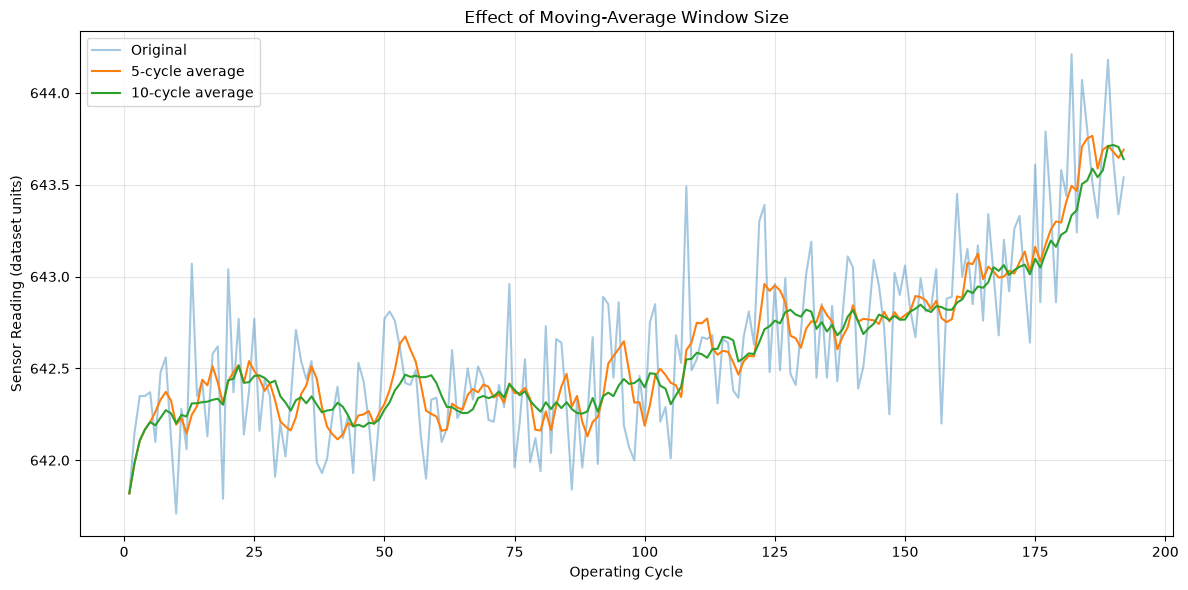

In [17]:

engine_1["sensor_2_smoothed_10"] = (
    engine_1["sensor_2"]
    .rolling(window=10, min_periods=1)
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"],
    label="Original",
    alpha=0.4
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2_smoothed"],
    label="5-cycle average"
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2_smoothed_10"],
    label="10-cycle average"
)

plt.title("Effect of Moving-Average Window Size")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Reading (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## Noise Reduction Findings

- Applied a 5-cycle moving-average filter to Sensor 2 for Engine 1.
- Compared original and smoothed readings using a time-series plot.
- Compared standard deviation before and after filtering.
- Investigated the effect of changing the moving-average window to 10 cycles.

### Observations

Record whether smoothing reduced visible fluctuations in your chart.
Compare the standard deviations and note any differences.
Describe whether the larger window appears to hide short-term changes.

### Limitation

Moving-average filtering can suppress genuine short-lived anomalies.
Original sensor measurements are retained for further analysis.


In [18]:
from sklearn.ensemble import IsolationForest

print("Isolation Forest imported successfully!")

Isolation Forest imported successfully!


# Step 6: Machine Learning-Based Anomaly Detection

We use the Isolation Forest algorithm to identify unusual
patterns in engine sensor readings and operating conditions.

In [19]:
# Select the 21 sensor columns
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

# Select the 3 operating-setting columns
operating_columns = [
    "operating_setting_1",
    "operating_setting_2",
    "operating_setting_3"
]

# Combine them into the model's input features
feature_columns = sensor_columns + operating_columns

X = df[feature_columns].copy()

print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing feature values:", X.isnull().sum().sum())

X.head()

Number of rows: 20631
Number of features: 24
Missing feature values: 0


,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,operating_setting_1,operating_setting_2,operating_setting_3
0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,...,8.4195,0.03,392,2388,100.0,39.06,23.4190,-0.0007,-0.0004,100.0
1,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,...,8.4318,0.03,392,2388,100.0,39.00,23.4236,0.0019,-0.0003,100.0
2,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,...,8.4178,0.03,390,2388,100.0,38.95,23.3442,-0.0043,0.0003,100.0
3,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,...,8.3682,0.03,392,2388,100.0,38.88,23.3739,0.0007,0.0000,100.0
4,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,...,8.4294,0.03,393,2388,100.0,38.90,23.4044,-0.0019,-0.0002,100.0


In [20]:
# Create the anomaly detection model
model = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

# Train the model and predict unusual rows
predictions = model.fit_predict(X)

# Save results in a separate DataFrame
df_results = df.copy()

df_results["anomaly_prediction"] = predictions
df_results["anomaly_score"] = model.decision_function(X)

print("Anomaly detection completed!")

Anomaly detection completed!


In [21]:
# Count normal rows and potential anomalies
print("Prediction counts:")
print(df_results["anomaly_prediction"].value_counts())

total_rows = len(df_results)

anomaly_count = (
    df_results["anomaly_prediction"] == -1
).sum()

print("\nTotal sensor records:", total_rows)
print("Potential anomalies:", anomaly_count)
print(
    "Percentage flagged:",
    round(anomaly_count / total_rows * 100, 2),
    "%"
)

Prediction counts:
anomaly_prediction
 1    20218
-1      413
Name: count, dtype: int64

Total sensor records: 20631
Potential anomalies: 413
Percentage flagged: 2.0 %


In [22]:
# Display the rows with the most unusual anomaly scores
potential_anomalies = (
    df_results[df_results["anomaly_prediction"] == -1]
    .sort_values("anomaly_score")
)

potential_anomalies[
    [
        "engine_id",
        "cycle",
        "sensor_2",
        "sensor_3",
        "sensor_4",
        "anomaly_score"
    ]
].head(10)

,engine_id,cycle,sensor_2,sensor_3,sensor_4,anomaly_score
9495,48,231,644.02,1609.54,1435.19,-0.094293
10119,51,211,643.68,1609.75,1419.91,-0.093600
10121,51,213,644.11,1606.60,1428.55,-0.081678
1913,9,201,644.04,1595.36,1428.43,-0.074618
3775,18,195,643.93,1601.00,1428.08,-0.074016
10120,51,212,643.37,1602.44,1432.71,-0.073927
1303,6,188,643.47,1600.63,1434.92,-0.071068
846,4,189,644.53,1612.11,1432.55,-0.067367
3933,19,158,643.34,1605.58,1433.97,-0.066789
10976,55,190,643.69,1604.96,1438.10,-0.064876


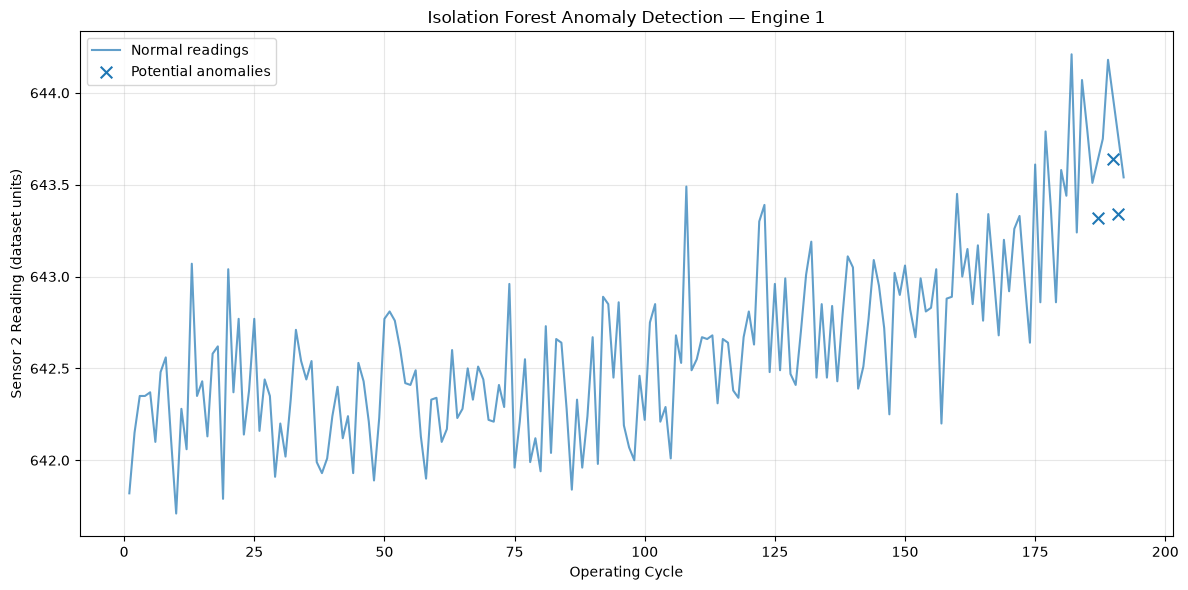

In [23]:
# Select results for Engine 1
engine_1_results = df_results[
    df_results["engine_id"] == 1
]

# Separate normal readings and potential anomalies
normal = engine_1_results[
    engine_1_results["anomaly_prediction"] == 1
]

anomalies = engine_1_results[
    engine_1_results["anomaly_prediction"] == -1
]

# Plot sensor readings
plt.figure(figsize=(12, 6))

plt.plot(
    normal["cycle"],
    normal["sensor_2"],
    label="Normal readings",
    alpha=0.7
)

plt.scatter(
    anomalies["cycle"],
    anomalies["sensor_2"],
    label="Potential anomalies",
    marker="x",
    s=70
)

plt.title("Isolation Forest Anomaly Detection — Engine 1")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Step 7: Anomaly Analysis and Evaluation

Analyze the distribution of potential anomalies across engines
and compare flagged readings with normal readings.

In [24]:
# Count potential anomalies for each engine
anomalies_per_engine = (
    df_results[df_results["anomaly_prediction"] == -1]
    .groupby("engine_id")
    .size()
    .sort_values(ascending=False)
)

print("Top 10 engines by number of flagged readings:")
print(anomalies_per_engine.head(10))

Top 10 engines by number of flagged readings:
engine_id
5     12
6     10
4      9
18     9
94     9
48     9
82     9
95     9
63     8
55     8
dtype: int64


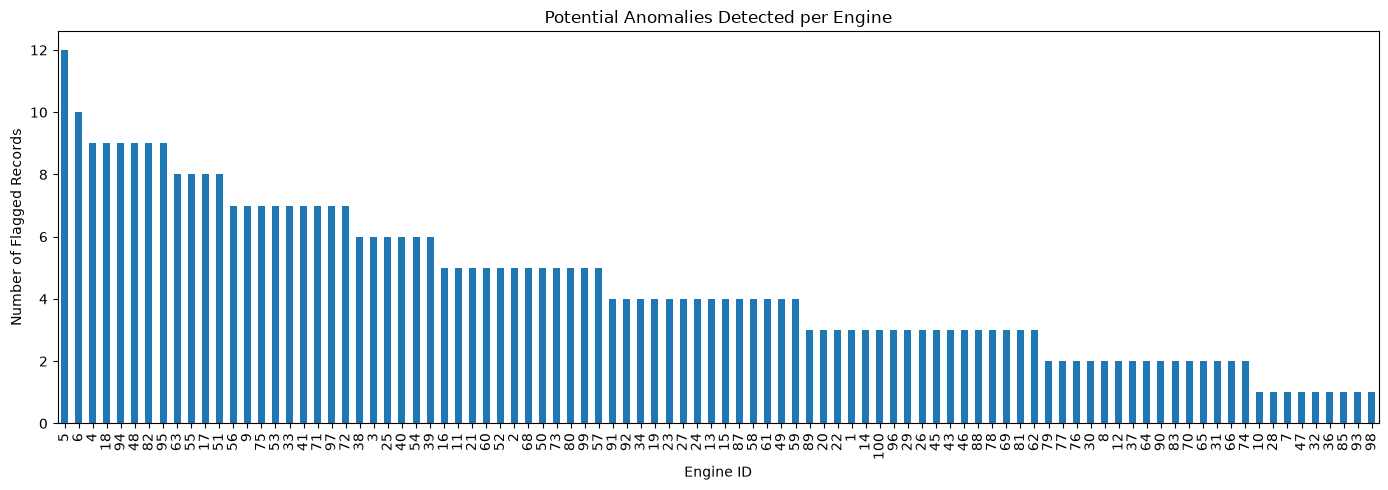

In [25]:
plt.figure(figsize=(14, 5))

anomalies_per_engine.plot(kind="bar")

plt.title("Potential Anomalies Detected per Engine")
plt.xlabel("Engine ID")
plt.ylabel("Number of Flagged Records")
plt.tight_layout()
plt.show()

In [26]:
normal_rows = df_results[
    df_results["anomaly_prediction"] == 1
]

anomaly_rows = df_results[
    df_results["anomaly_prediction"] == -1
]

comparison = pd.DataFrame({
    "Normal Mean": normal_rows[sensor_columns].mean(),
    "Anomaly Mean": anomaly_rows[sensor_columns].mean(),
    "Normal Std": normal_rows[sensor_columns].std(),
    "Anomaly Std": anomaly_rows[sensor_columns].std()
})

comparison["Absolute Mean Difference"] = (
    comparison["Anomaly Mean"] - comparison["Normal Mean"]
).abs()

comparison = comparison.sort_values(
    "Absolute Mean Difference",
    ascending=False
)

comparison.head(10)

,Normal Mean,Anomaly Mean,Normal Std,Anomaly Std,Absolute Mean Difference
sensor_9,9064.285828,9112.097409,19.477295,59.640378,47.811581
sensor_14,8143.003807,8180.415133,16.880820,53.510783,37.411327
sensor_4,1408.565604,1426.957530,8.624199,8.628328,18.391926
sensor_3,1590.297302,1601.577724,5.914773,6.370139,11.280422
sensor_17,393.151202,396.121065,1.489884,1.587227,2.969863
sensor_7,553.401307,551.723075,0.851722,0.928740,1.678232
sensor_12,521.441651,520.033874,0.709270,0.778748,1.407777
sensor_2,642.662724,643.572349,0.483408,0.491020,0.909624
sensor_11,47.530191,48.078547,0.255563,0.267720,0.548356
sensor_20,38.823472,38.463753,0.173418,0.181632,0.359719


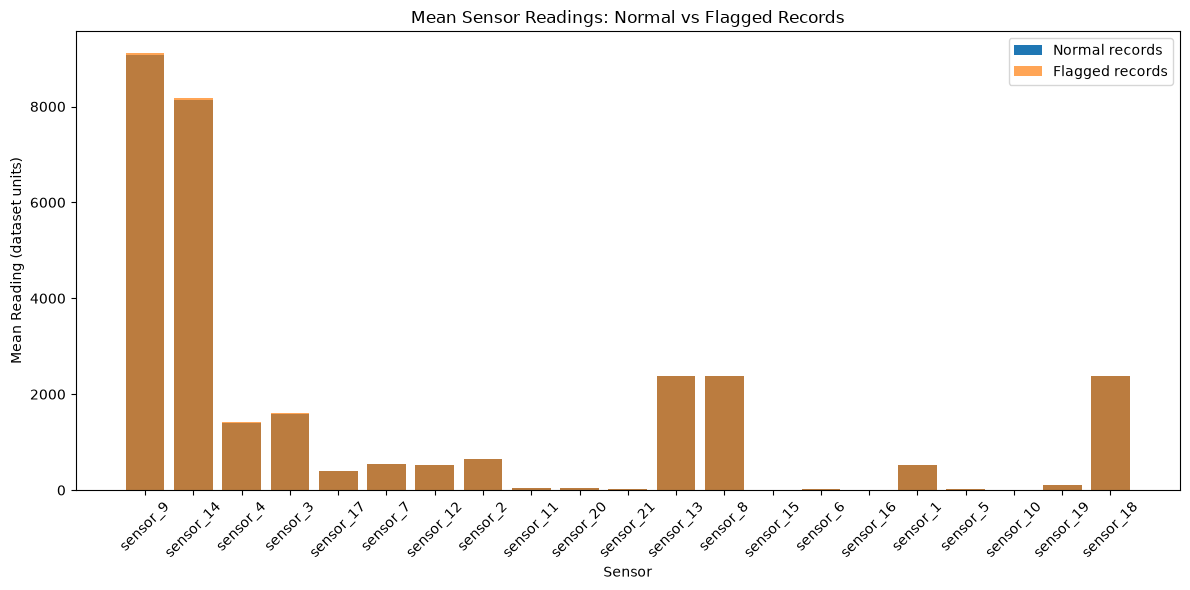

In [27]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison.index,
    comparison["Normal Mean"],
    label="Normal records"
)

plt.bar(
    comparison.index,
    comparison["Anomaly Mean"],
    label="Flagged records",
    alpha=0.7
)

plt.title("Mean Sensor Readings: Normal vs Flagged Records")
plt.xlabel("Sensor")
plt.ylabel("Mean Reading (dataset units)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
total_records = len(df_results)

normal_count = (
    df_results["anomaly_prediction"] == 1
).sum()

anomaly_count = (
    df_results["anomaly_prediction"] == -1
).sum()

summary = pd.DataFrame({
    "Category": ["Normal records", "Potential anomalies"],
    "Count": [normal_count, anomaly_count],
    "Percentage": [
        round(normal_count / total_records * 100, 2),
        round(anomaly_count / total_records * 100, 2)
    ]
})

summary

,Category,Count,Percentage
0,Normal records,20218,98.0
1,Potential anomalies,413,2.0


## Step 7: Findings

1. Isolation Forest identified a subset of sensor records as
   potential anomalies.

2. The engine-wise analysis showed which engines had the highest
   numbers of flagged records.

3. Comparing normal and flagged records revealed differences
   in the distributions of selected sensor readings.

4. The model used sensor measurements and operating settings
   without confirmed anomaly labels.

5. The results are exploratory and require further evaluation
   before being interpreted as evidence of real engine faults.

# Step 8: Testing with Synthetic Sensor Anomalies

Create artificial sensor anomalies and evaluate whether the
trained Isolation Forest model identifies the modified records.

In [29]:
# Create a separate copy of the feature data
X_test = X.copy()

# Make the experiment reproducible
rng = np.random.default_rng(42)

# Select 100 distinct rows for artificial anomalies
synthetic_indices = rng.choice(
    X_test.index.to_numpy(),
    size=100,
    replace=False
)

# Keep the original readings for comparison
X_test_original = X_test.copy()

print("Test dataset shape:", X_test.shape)
print("Synthetic anomaly cases:", len(synthetic_indices))

Test dataset shape: (20631, 24)
Synthetic anomaly cases: 100


In [30]:
# Calculate the original mean and standard deviation of Sensor 2
sensor_2_mean = X["sensor_2"].mean()
sensor_2_std = X["sensor_2"].std()

# Artificially increase Sensor 2 for selected rows
X_test.loc[synthetic_indices, "sensor_2"] = (
    X_test.loc[synthetic_indices, "sensor_2"]
    + 5 * sensor_2_std
)

print("Synthetic sensor anomalies created!")

print(
    X_test.loc[
        synthetic_indices,
        ["sensor_2"]
    ].head()
)

Synthetic sensor anomalies created!
         sensor_2
9011   645.380266
19381  644.910266
13805  644.980266
9607   645.250266
9262   645.900266


In [31]:
# Predict using the model trained in Step 6
test_predictions = model.predict(X_test)

# Count how many injected cases were flagged
injected_flags = (
    test_predictions[
        X_test.index.get_indexer(synthetic_indices)
    ] == -1
).sum()

print("Injected anomalies:", len(synthetic_indices))
print("Injected cases flagged:", injected_flags)

print(
    "Detection rate on injected cases:",
    round(injected_flags / len(synthetic_indices) * 100, 2),
    "%"
)

Injected anomalies: 100
Injected cases flagged: 4
Detection rate on injected cases: 4.0 %


In [32]:
# Predictions on the original feature dataset
original_predictions = model.predict(X)

# Number of records flagged in each dataset
original_flagged = (original_predictions == -1).sum()
test_flagged = (test_predictions == -1).sum()

comparison_results = pd.DataFrame({
    "Dataset": [
        "Original dataset",
        "Dataset with synthetic modifications"
    ],
    "Total Records": [
        len(X),
        len(X_test)
    ],
    "Flagged Records": [
        original_flagged,
        test_flagged
    ],
    "Flagged Percentage": [
        round(original_flagged / len(X) * 100, 2),
        round(test_flagged / len(X_test) * 100, 2)
    ]
})

comparison_results

,Dataset,Total Records,Flagged Records,Flagged Percentage
0,Original dataset,20631,413,2.00
1,Dataset with synthetic modifications,20631,415,2.01


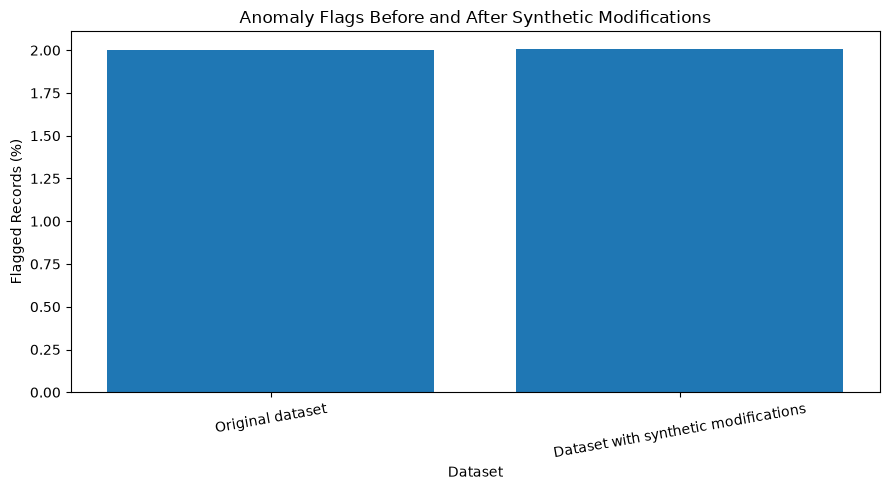

In [33]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_results["Dataset"],
    comparison_results["Flagged Percentage"]
)

plt.title("Anomaly Flags Before and After Synthetic Modifications")
plt.xlabel("Dataset")
plt.ylabel("Flagged Records (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## Step 8: Synthetic Anomaly Test Findings

1. A separate test dataset was created without modifying the
   original sensor dataset.

2. Artificial changes were introduced into Sensor 2 for
   100 selected records.

3. The trained Isolation Forest model was applied to the
   modified dataset.

4. The detection rate on the injected cases was recorded.

5. This experiment evaluates detection of the specific
   artificial changes used in the test. It does not establish
   real-world engine fault detection accuracy.

# Step 9: Sensor Anomaly Detection Dashboard

This section summarizes the dataset, model predictions,
engine-level anomaly counts, and selected sensor readings.